In [1]:
from pycircstat2 import Circular

拟合的均值 (mu): -1.4117 弧度 (-80.89 度), x = 1
拟合的集中参数 (kappa): 3.7578


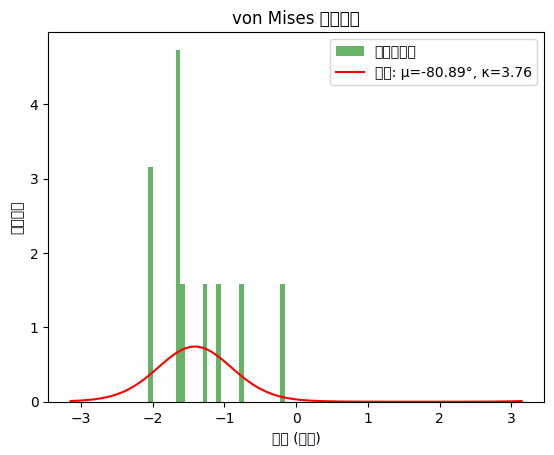

In [30]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# 生成 von Mises 分布的模拟数据
np.random.seed(42)
mu_true = np.deg2rad(280)  # 真实均值（30度）
kappa_true = 4  # 集中参数
angles = stats.vonmises.rvs(kappa_true, loc=mu_true, size=10)  # 生成 1000 个数据点
# 拟合 von Mises 分布
kappa_fit, mu_fit ,x= stats.vonmises.fit(angles)  # 只拟合 kappa 和 mu

# 转换回角度方便查看
mu_fit_deg = np.rad2deg(mu_fit)

print(f"拟合的均值 (mu): {mu_fit:.4f} 弧度 ({mu_fit_deg:.2f} 度), x = {x}")
print(f"拟合的集中参数 (kappa): {kappa_fit:.4f}")
# 生成拟合的分布曲线
theta = np.linspace(-np.pi, np.pi, 100)  # 角度范围 (-π 到 π)
pdf = stats.vonmises.pdf(theta, kappa_fit, loc=mu_fit)

# 绘图
plt.hist(angles, bins=30, density=True, alpha=0.6, color='g', label="数据直方图")
plt.plot(theta, pdf, 'r-', label=f'拟合: μ={mu_fit_deg:.2f}°, κ={kappa_fit:.2f}')
plt.xlabel("角度 (弧度)")
plt.ylabel("概率密度")
plt.title("von Mises 分布拟合")
plt.legend()
plt.show()



In [35]:
t=np.load("EHT-Imaging/t.npy")

Mean: -1.3012
Standard Deviation (sigma): 0.2209


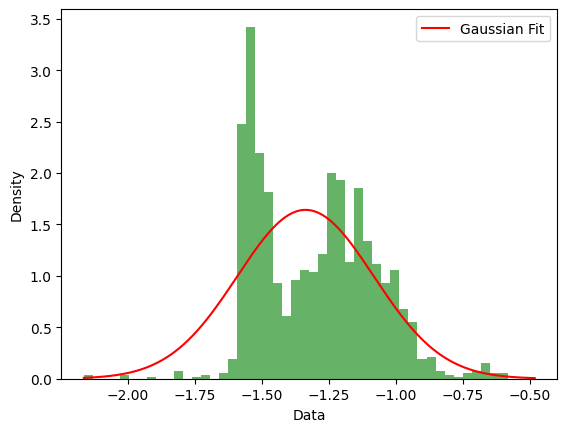

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import curve_fit

# 给定的随机数列
data = t

# 计算数据的均值和标准差（sigma）
mean, std_dev = np.mean(data), np.std(data)

print(f"Mean: {mean:.4f}")
print(f"Standard Deviation (sigma): {std_dev:.4f}")

# 高斯拟合函数
def gaussian(x, amplitude, mean, sigma):
    return amplitude * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

# 创建一个直方图
count, bins, ignored = plt.hist(data, bins=50, density=True, alpha=0.6, color='g')

# 使用 curve_fit 函数进行高斯拟合
popt, _ = curve_fit(gaussian, bins[:-1], count, p0=[1, mean, std_dev])

# 生成拟合的高斯曲线
x_values = np.linspace(min(data), max(data), 1000)
y_values = gaussian(x_values, *popt)

# 绘制高斯拟合曲线
plt.plot(x_values, y_values, label="Gaussian Fit", color="r")
plt.xlabel("Data")
plt.ylabel("Density")
plt.legend()
plt.show()
